# 02 Deep Tabular Model

In [1]:
import pandas as pd
import numpy as np
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import GroupKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import shap
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Set random state
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Load data
df = pd.read_csv('../dataset/pd_speech_features.csv', header=1)
X = df.drop(['id', 'class'], axis=1)
y = df['class']
groups = df['id']

# Print basic stats
print(f"Data shape: {df.shape}")
print(f"Patients: {groups.nunique()}")


Data shape: (756, 755)
Patients: 252


In [2]:
import sys
sys.path.append('../src')
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from deep_tabular_model import DeepTabularModel

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

gkf = GroupKFold(n_splits=5)
metrics = {'acc': [], 'prec': [], 'rec': [], 'f1': [], 'auc': []}

for fold, (train_idx, test_idx) in enumerate(gkf.split(X, y, groups)):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    
    # 1. VarianceThreshold
    vt = VarianceThreshold(threshold=0.01)
    X_train = vt.fit_transform(X_train)
    X_test = vt.transform(X_test)
    
    # 2. StandardScaler
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)
    
    # 3. SelectKBest
    skb = SelectKBest(f_classif, k=50)
    X_train = skb.fit_transform(X_train, y_train)
    X_test = skb.transform(X_test)
    
    # 4. SMOTE
    smote = SMOTE(random_state=RANDOM_STATE)
    X_train, y_train = smote.fit_resample(X_train, y_train)
    
    # Prepare PyTorch Tensors
    X_train_t = torch.FloatTensor(X_train).to(device)
    y_train_t = torch.FloatTensor(y_train.values).to(device)
    X_test_t = torch.FloatTensor(X_test).to(device)
    y_test_t = torch.FloatTensor(y_test.values).to(device)
    
    train_ds = TensorDataset(X_train_t, y_train_t)
    train_dl = DataLoader(train_ds, batch_size=32, shuffle=True)
    
    # Model
    model = DeepTabularModel(num_features=50, d_model=32, nhead=4, num_layers=2, dim_feedforward=64, dropout=0.2).to(device)
    
    # Optimizer & Scheduler
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=60)
    
    # Training Loop
    model.train()
    losses = []
    for epoch in range(60):
        for bx, by in train_dl:
            optimizer.zero_grad()
            logits = model(bx)
            loss = criterion(logits, by)
            loss.backward()
            optimizer.step()
        scheduler.step()
        losses.append(loss.item())
        
    # Evaluation
    model.eval()
    with torch.no_grad():
        test_logits = model(X_test_t)
        probs = torch.sigmoid(test_logits).cpu().numpy()
        preds = (probs >= 0.5).astype(int)
        
    y_test_np = y_test_t.cpu().numpy()
    
    metrics['acc'].append(accuracy_score(y_test_np, preds))
    metrics['prec'].append(precision_score(y_test_np, preds))
    metrics['rec'].append(recall_score(y_test_np, preds))
    metrics['f1'].append(f1_score(y_test_np, preds))
    metrics['auc'].append(roc_auc_score(y_test_np, probs))
    print(f"Fold {fold+1} Accuracy: {metrics['acc'][-1]:.4f}")

print("\nDeep Tabular Model Results (Mean Ã‚Â± Std):")
for m in metrics:
    print(f"{m.upper()}: {np.mean(metrics[m]):.4f} Ã‚Â± {np.std(metrics[m]):.4f}")

# Save results for paper
pd.DataFrame({
    'Metric': [m.upper() for m in metrics.keys()],
    'Value': [f"{np.mean(metrics[m]):.4f} Ã‚Â± {np.std(metrics[m]):.4f}" for m in metrics]
}).to_csv("deep_model_results.csv", index=False)


Using device: cpu


Fold 1 Accuracy: 0.6405


Fold 2 Accuracy: 0.7843


Fold 3 Accuracy: 0.8333


Fold 4 Accuracy: 0.7133


Fold 5 Accuracy: 0.7733

Deep Tabular Model Results (Mean Ã‚Â± Std):
ACC: 0.7490 Ã‚Â± 0.0663
PREC: 0.8568 Ã‚Â± 0.0447
REC: 0.7963 Ã‚Â± 0.0666
F1: 0.8245 Ã‚Â± 0.0511
AUC: 0.7846 Ã‚Â± 0.0605


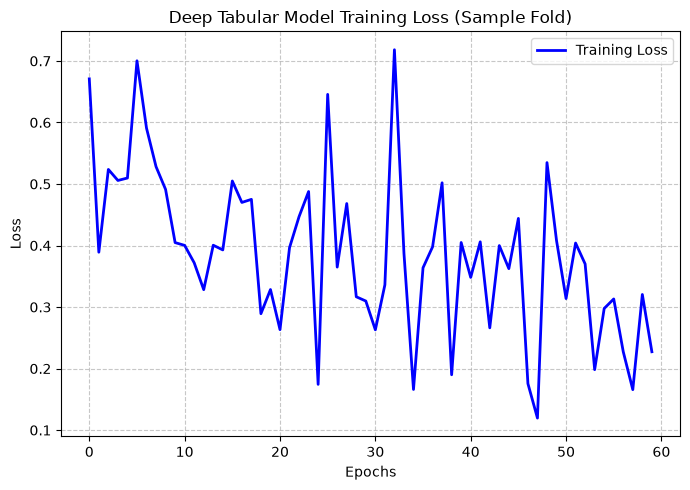

In [3]:

import matplotlib.pyplot as plt

# The deep_tabular_model.py train function returns a list of epoch losses
# In cell 2, it was: model, losses = deep_tabular_model.train_model(...)
# We just need to plot it from the last fold

plt.figure(figsize=(7, 5))
plt.plot(losses, label='Training Loss', color='blue', linewidth=2)
plt.title('Deep Tabular Model Training Loss (Sample Fold)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.savefig('../figures/training_loss.png', dpi=300)
plt.show()
